In [1]:
%matplotlib inline


# Scientific Computation Lab 8 solution







### Part 1
In lecture, we saw that FFTs could be used to analyze the frequency content of time series. In part 1 of this lab, you will learn how to use them to differentiate periodic functions.

We will work with a Gaussian function, $f(x) = exp(-\alpha x^2)$
with $-5 \le x \le 5$. We will choose $\alpha$ so that the Gaussian is sufficiently narrow for f and several of its derivatives to be near zero at the boundaries (why is this important?). The function below will generate this Gaussian with $x$ and $\alpha$ provided as input.

In [4]:
import numpy as np
def gauss(x,alpha):
    return np.exp(-alpha*x**2)

### Task 1: Fourier coefficients

1) Complete the cell below so that it generates a grid, $x$, with $N=100$ points in the interval [-5, 5).
One approach is to first generate $N+1$ points from -5 to 5, and then remove the $N+1th$ point corresponding to $x=5$.

In [2]:
import numpy as np
N=100
alpha = 4
#Add code here
x = np.linspace(-5,5,N+1)
x = x[:-1]

2) Now generate the Guassian and plot $f(x)$. You should use a log scale for the vertical axis. Is $\alpha$ sufficiently large?

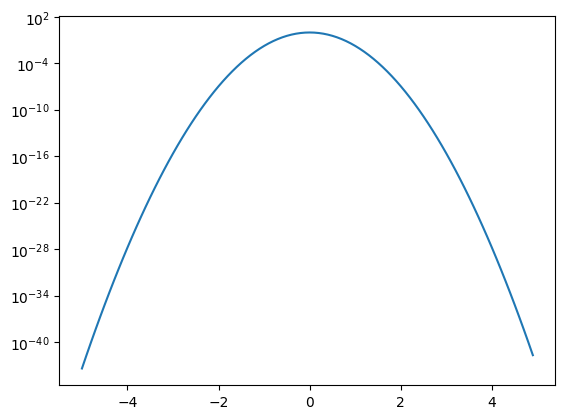

: 

In [ ]:
import matplotlib.pyplot as plt
#add code here
plt.figure()
f=gauss(x,alpha)
plt.semilogy(x,f)



*Add answer here*

2) Now, compute the Gaussian's Fourier coefficients ($c_n$) and plot $|c_n|$ on a semilog plot. Compute a new Gaussian, $g$  with $\alpha=1$. 
Compute its Fourier coefficients and add them to your plot. Why are the two curves different?

In [ ]:
#add code here


*Add answer here*

### Task 2: Differentiation

For time series, the *kth* Fourier coefficient corresponds to a frequency, $\phi_k= k/\tau$ where $\tau$ is related to the timespan of the signal. For a spatially varying function, the *kth* coefficient corresponds to a wavenumber, $\alpha_k=2 \pi k/l$ where, for our example above, $l=10$. The wavenumber plays a key role in Fourier differentiation. If the Fourier coefficients of $f(x)$ are $c_k$, then the Fourier coefficients of $df/dx$ are $i \alpha_k c_k$.

The basic steps then are, i) construct $\alpha_k$, ii) compute $c_k$, iii) compute the inverse discrete Fourier transform of $i \alpha_k c_k$. 

1) Construct $\alpha_k$ for $f(x)$ from our example above. Both $k$ and $\alpha$ will have to be in "fft order", $k=0,1,...,N/2-1,-N/2,-N/2+1,...,-1$

In [ ]:
k = np.arange(-N/2,N/2)
k = np.fft.fftshift(n)
#add code here

2) Now, compute $df$, an arrray which is $N$ times the inverse FFT of $i\alpha c$. Here $\alpha$ is an array of wavenumbers, and $c$ is an array of Fourier coefficients.

In [19]:
#add code here

The code below will plot $df$ and the exact derivative of the Gaussian. If $df$ has been constructed correctly, the two should be extremely close.

In [ ]:
plt.figure()
plt.plot(x,df.real,'x--')
plt.plot(x,-2*alpha*x*f)
plt.xlabel('x')
plt.ylabel('df/dx')
plt.legend(('computed','exact'))

3) Repeat the steps above with *N=25* and *N=50*. Compute the error, $\epsilon(x) = |df_{computed}-df_{exact}|$ for all three values of *N* and plot them on a figure.

In [ ]:
#add code here



4) A very important idea is "grid convergence" which is connected to the rate at which the error decreases as $\Delta x$ decreases (or as $N$ increases). For a well-posed method, for sufficiently small $\Delta x$, the solution should be *grid independent* -- further reductions in the grid spacing will not meaningfully reduce the error any further. This typically occurs when the error is close to ~$1e-15$. At (approximately) what value of $N$ does the differentiation of the Gaussian (with $\alpha=4$) become grid independent?

In [ ]:
#Compute error for a few values of N and display results


### Part 2

In this (short) scond part of the lab, you will use Welch's method to estimate the frequency of oscillation in simulation results for the predator-prey system we encountered previously.

The cell below will compute a numerical solution storing the results in $\tt x$ and $\tt y$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from time import time
from scipy.signal import welch

a = 4
b = 1
delta = 0.5
Dt = 0.1
Nt = 1010
t = np.linspace(0,Nt*Dt,Nt+1)
z0 = np.array([delta+1/b,delta+a/b])

def RHS(t,z,a):
    """
    This function has been written in a slightly inefficient way to enhance clarity
    """
    x,y = z[0],z[1]
    #Add code here to compute and return [dx/dt,dydt]
    dxdt = a*x - b*x*y
    dydt = -y + b*x*y
    return [dxdt,dydt]
    
    
sol = solve_ivp(RHS, [t[0],t[-1]], z0,t_eval=t, args=(a,),method='BDF',atol=1e-6,rtol=1e-6) 

#Add code to obtain and display solution
z = sol.y

plt.figure()
plt.plot(t/(np.pi),z.T)
plt.xlabel(r'$t/(\pi)$')
plt.legend(('x(t)','y(t)'))
plt.grid()
x,y = z[0,:],z[1,:]

Complete the code below so that it uses Welch's method to estimate the frequency of oscillation. You should remove the first 100 or so points from ${\tt x}$ before you use Welch's method to remove the influence of the initial condition. Make a plot of $P_{xx}$ vs. $f$ and find the frequency at which $P_{xx}$ is largest. Is this frequency close to what you expect? (Note: the default parameters used by ${\tt scipy.signal.welch}$ should be ok here, but sometimes it can be helpful to change ${\tt nperseg}$ or modify the timespan or timestep used for the simulation.)

In [ ]:
from scipy.signal import welch
#add code here